In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))

In [2]:
import numpy as np

In [3]:
from src.data import load_csv
from src.models import SimpleLinearRegression

In [4]:
df = load_csv('../data/hour.csv')

In [5]:
df.head()

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,1


In [6]:
df.sort_values(by=['dteday', 'hr'])

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,16
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,40
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,32
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,13
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,119
17375,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,89
17376,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,90
17377,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,61


In [ ]:
class MultipleLinearRegression:
    def __init__(self):
        self.beta_hat = None
        self.intercept_ = None
        self.coef_ = None
        
    def _add_intercept(self, X):
        X = np.asarray(X, dtype=float)

        return np.c_[np.ones(X.shape[0]), X]

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

    
        X_design = self._add_intercept(X)

        XTX = X_design.T @ X_design

        XTy = X_design.T @ y

        self.beta_hat = np.linalg.solve(XTX, XTy)
        self.intercept_ = self.beta_hat[0]
        self.coef_ = self.beta_hat[1:]

        return self

    def predict(self, X):
        if self.beta_hat is None:
            raise ValueError("Model is not fitted yet! Call fit() first")
        X = np.asarray(X, dtype=float)
        X_test_design = self._add_intercept(X)
        
        return X_test_design @ self.beta_hat

    def residual(self, X, y):
        y = np.asarray(y, dtype=float)
        y_pred = self.predict(X)
        resid = y - y_pred
        return resid

    def r2_score(self,X ,y):
        y = np.asarray(y, dtype=float)

        y_pred = self.predict(X)

        ss_residual = np.sum((y - y_pred) ** 2)

        ss_total = np.sum((y - np.mean(y)) ** 2)

        if ss_total == 0.0:
            return 0

        return 1 - (ss_residual / ss_total)

In [8]:
from sklearn.model_selection import train_test_split

Toy Check 

In [9]:
y = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20]
x = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

mlr = MultipleLinearRegression()
mlr.fit(x, y)
print(mlr.beta_hat)

[0. 2.]


In [10]:
features = ['atemp', 'hum', 'windspeed']

X = df[features]
y = df['cnt']

X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=False, test_size=0.2)

## Before scaling

In [11]:
model = MultipleLinearRegression()

In [12]:
model.fit(X_train, y_train)

print(model.intercept_, ",  : ", model.coef_)
print("train R2: ", model.r2_score(X_train, y_train))
print("test R2: ", model.r2_score(X_test, y_test))

131.80296387524038 ,  :  [ 391.12100534 -248.65229911   55.55415169]
train R2:  0.2775778804027268
test R2:  0.09631659065685227


In [13]:
Xd = model._add_intercept(X_train) 
resid = model.residual(X_train, y_train)
print(Xd.T @ resid)

[ 2.42880560e-09  9.21474452e-10 -7.38396011e-10  2.26366481e-10]


This is condition number, which tells us about the curve of our dear loss function.

In [14]:
np.linalg.cond(Xd.T @ Xd)

np.float64(154.1038424886802)

### Compare our class with SKLEARN's Linear Regression.

In [15]:
from sklearn.linear_model import LinearRegression
features = ['atemp', 'hum', 'windspeed']

X = df[features]
y = df['cnt']

X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=False, test_size=0.2)

In [16]:
y_test

13903    283
13904    253
13905    261
13906    306
13907    445
        ... 
17374    119
17375     89
17376     90
17377     61
17378     49
Name: cnt, Length: 3476, dtype: int64

In [17]:
sk = LinearRegression()

In [18]:
sk.fit(X_train, y_train)

print(sk.intercept_, ", Coeffs: ", sk.coef_)

131.80296387524461 , Coeffs:  [ 391.12100534 -248.65229911   55.55415169]


In [19]:
sk.predict(X_test)

array([298.81839558, 303.64950813, 313.73617992, ...,  92.48634709,
       106.6772971 ,  84.29859018], shape=(3476,))

In [20]:
print(np.allclose(model.beta_hat[1:], sk.coef_), np.isclose(model.intercept_, sk.intercept_))

True True


In [21]:
y_pred = model.predict(X_test)


import matplotlib.pyplot as plt
import seaborn as sea

### Visual plot between y_test and y_pred, and the 1:1 Ideal Fit line ! 

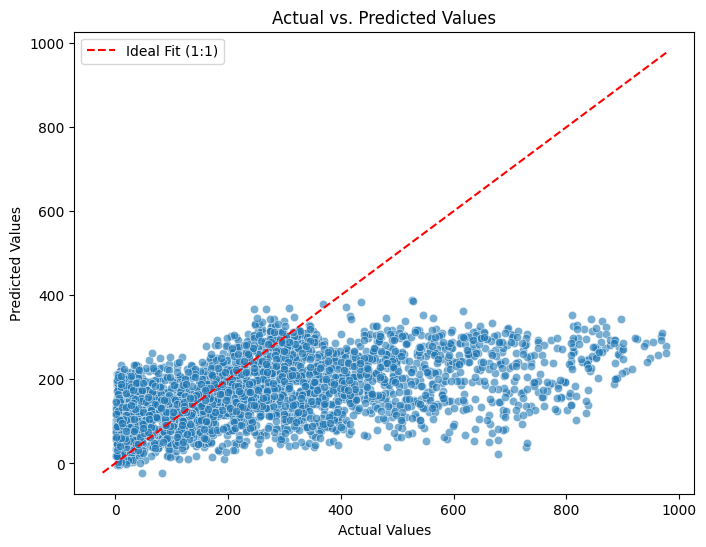

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set figure size
plt.figure(figsize=(8, 6))

# Create scatter plot (actual on x-axis, predicted on y-axis)
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)

# Add a red 1:1 line for perfect predictions (where actual == predicted)
min_val = min(min(y_test), min(y_pred))
max_val = max(max(y_test), max(y_pred))
plt.plot(
    [min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Ideal Fit (1:1)'
)

plt.title('Actual vs. Predicted Values')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.legend()
plt.show()


using class MultipleLinearRegression: 131.80296387524038 , Coeffs:  [ 391.12100534 -248.65229911   55.55415169]

using LinearRegression: 131.80296387524461 , Coeffs:  [ 391.12100534 -248.65229911   55.55415169]


## AFTER SCALING !! 

In [25]:
from sklearn.preprocessing import StandardScaler

In [28]:
scaler = StandardScaler()

X_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.fit_transform(X_test)


In [33]:
model = MultipleLinearRegression()

model.fit(X_sc, y_train)

print(model.beta_hat)
resid = model.residual(X_sc, y_train)
print("MSE Train: ", np.mean(resid) ** 2)
print("Train R2 Score: ", model.r2_score(X_sc, y_train))



[174.63914263  69.07492924 -49.2797021    6.83420389]
MSE Train:  5.302352891803483e-28
Train R2 Score:  0.277577880402727


In [35]:
y_pred = model.predict(X_test_sc)

resid = model.residual(X_test_sc, y_test)
print("MSE Test: ", np.mean((resid)**2))
print("Test R2 Score: ", model.r2_score(X_test_sc, y_test))


MSE Test:  41334.90295775855
Test R2 Score:  0.14972473571269218





Before scaling: Intercept and Coefficients 131.80296387524038 ,  :  [ 391.12100534 -248.65229911   55.55415169]
train R2:  0.2775778804027268
test R2:  0.09631659065685227

[174.63914263  69.07492924 -49.2797021    6.83420389]
MSE Train:  5.302352891803483e-28
Train R2 Score:  0.277577880402727
MSE Test:  41334.90295775855
Test R2 Score:  0.14972473571269218


### UPDATING CLASS FOR RESIDUAL ANALYSIS.

In [ ]:
class MultipleLinearRegression:
    def __init__(self):
        self.beta_hat = None
        self.intercept_ = None
        self.coef_ = None
        
    def _add_intercept(self, X):
        X = np.asarray(X, dtype=float)

        return np.c_[np.ones(X.shape[0]), X]

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

    
        X_design = self._add_intercept(X)

        XTX = X_design.T @ X_design

        XTy = X_design.T @ y

        self.beta_hat = np.linalg.solve(XTX, XTy)
        self.intercept_ = self.beta_hat[0]
        self.coef_ = self.beta_hat[1:]

        return self

    def predict(self, X):
        if self.beta_hat is None:
            raise ValueError("Model is not fitted yet! Call fit() first")
        X = np.asarray(X, dtype=float)
        X_test_design = self._add_intercept(X)
        
        return X_test_design @ self.beta_hat

    def residual(self, X, y):
        y = np.asarray(y, dtype=float)
        y_pred = self.predict(X)
        resid = y - y_pred
        return resid

    def r2_score(self,X ,y):
        y = np.asarray(y, dtype=float)

        y_pred = self.predict(X)

        ss_residual = np.sum((y - y_pred) ** 2)

        ss_total = np.sum((y - np.mean(y)) ** 2)

        if ss_total == 0.0:
            return 0

        return 1 - (ss_residual / ss_total)